In [1]:
!pip -q install onnx onnxscript onnxruntime fastapi uvicorn python-multipart httpx pytest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 98.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 34.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


In [2]:
import hashlib, json, os, random, shutil, subprocess, sys, time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
IMG_SIZE = 224
BATCH = 32
EPOCHS = 8
LR = 1e-4

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("reports", exist_ok=True)
print("device:", device)

device: cuda


In [3]:
import kagglehub

root = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
for folder, subfolders, files in os.walk(root):
    print(folder.replace(root, "") or "/", "->", len(files), "files")

DATA_DIR = [folder for folder, subfolders, _ in os.walk(root)
            if "512" in folder and set(subfolders) == {"def_front", "ok_front"}][0]
print("using:", DATA_DIR)

100%|██████████| 100M/100M [00:06<00:00, 16.8MB/s] 

Extracting files...


/ -> 0 files
/casting_512x512 -> 0 files
/casting_512x512/casting_512x512 -> 0 files
/casting_512x512/casting_512x512/def_front -> 781 files
/casting_512x512/casting_512x512/ok_front -> 519 files
/casting_data -> 0 files
/casting_data/casting_data -> 0 files
/casting_data/casting_data/train -> 0 files
/casting_data/casting_data/train/def_front -> 3758 files
/casting_data/casting_data/train/ok_front -> 2875 files
/casting_data/casting_data/test -> 0 files
/casting_data/casting_data/test/def_front -> 453 files
/casting_data/casting_data/test/ok_front -> 262 files
using: /root/.cache/kagglehub/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/versions/2/casting_512x512/casting_512x512


folder -> index: {'def_front': 0, 'ok_front': 1}
defective: 781 images (60%)
normal: 519 images (40%)


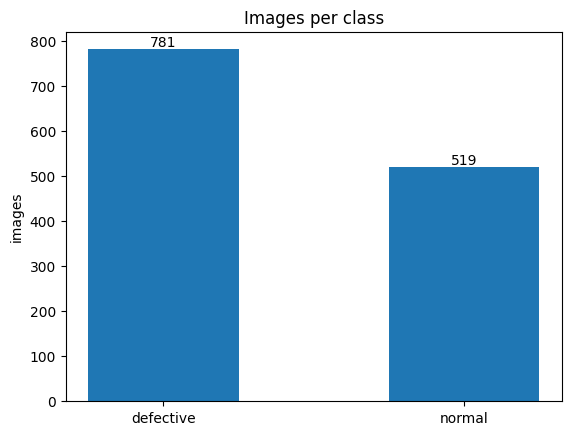

In [4]:
full = datasets.ImageFolder(DATA_DIR)
print("folder -> index:", full.class_to_idx)
assert full.classes == ["def_front", "ok_front"]
CLASS_NAMES = ["defective", "normal"]

labels = np.array(full.targets)
counts = np.bincount(labels)
for name, count in zip(CLASS_NAMES, counts):
    print(f"{name}: {count} images ({count / len(labels):.0%})")

bars = plt.bar(CLASS_NAMES, counts, width=0.5)
plt.bar_label(bars)
plt.title("Images per class")
plt.ylabel("images")
plt.savefig("reports/class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
sizes, modes, seen, keep = set(), set(), set(), []
for i, (path, _) in enumerate(full.samples):
    with Image.open(path) as image:
        sizes.add(image.size); modes.add(image.mode)
    file_hash = hashlib.md5(open(path, "rb").read()).hexdigest()
    if file_hash not in seen:
        seen.add(file_hash); keep.append(i)
keep = np.array(keep)

print("image sizes:", sizes)
print("colour modes:", modes)
print(f"exact duplicates removed: {len(full) - len(keep)}  ->  {len(keep)} images kept")

image sizes: {(512, 512)}
colour modes: {'RGB'}
exact duplicates removed: 0  ->  1300 images kept


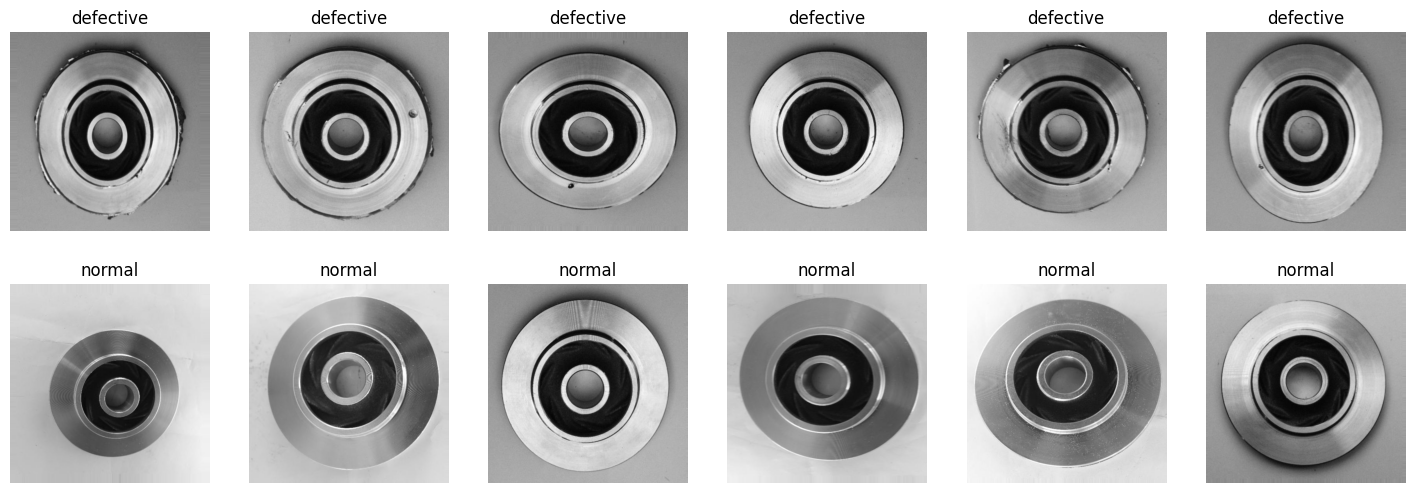

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for row, class_index in enumerate([0, 1]):
    for ax, i in zip(axes[row], np.where(labels == class_index)[0][:6]):
        ax.imshow(Image.open(full.samples[i][0]), cmap="gray")
        ax.set_title(CLASS_NAMES[class_index]); ax.axis("off")
plt.show()

In [7]:
train_idx, rest_idx = train_test_split(keep, test_size=0.30, stratify=labels[keep], random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=labels[rest_idx], random_state=SEED)

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    c = np.bincount(labels[idx])
    print(f"{name}: {len(idx)} images  (defective {c[0]}, normal {c[1]})")

train: 910 images  (defective 547, normal 363)
val: 195 images  (defective 117, normal 78)
test: 195 images  (defective 117, normal 78)


In [8]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = Subset(datasets.ImageFolder(DATA_DIR, train_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(DATA_DIR, eval_tf), val_idx)
test_ds = Subset(datasets.ImageFolder(DATA_DIR, eval_tf), test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2)

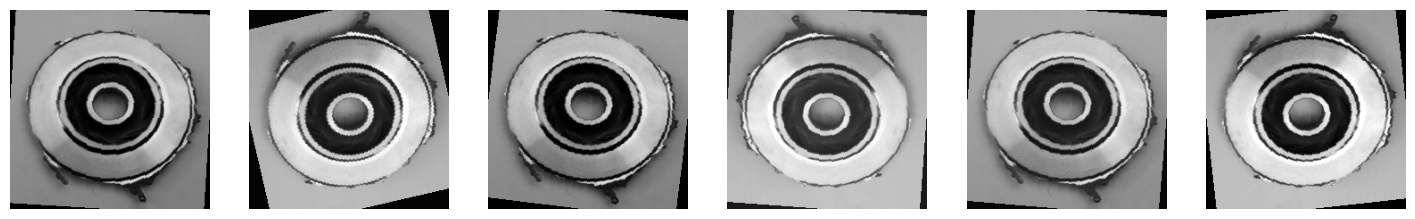

In [9]:
augment_only = transforms.Compose(train_tf.transforms[:-2])
original = Image.open(full.samples[train_idx[0]][0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax in axes:
    ax.imshow(augment_only(original)); ax.axis("off")
plt.show()

In [10]:
train_counts = np.bincount(labels[train_idx])
class_weights = len(train_idx) / (2 * train_counts)
print("train counts :", dict(zip(CLASS_NAMES, train_counts)))
print("class weights:", dict(zip(CLASS_NAMES, class_weights.round(3))))

criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))

train counts : {'defective': np.int64(547), 'normal': np.int64(363)}
class weights: {'defective': np.float64(0.832), 'normal': np.float64(1.253)}


In [11]:
model = models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 201MB/s]


In [12]:
def predict(loader):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs = torch.softmax(model(x.to(device)), dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(y.numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)

history = {"train_loss": [], "val_f1": []}
best_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(x)
    train_loss = running_loss / len(train_ds)

    val_probs, val_true = predict(val_loader)
    val_f1 = f1_score(val_true, val_probs.argmax(1), pos_label=0)
    history["train_loss"].append(train_loss)
    history["val_f1"].append(val_f1)

    note = ""
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), "best.pt")
        note = "  <- best so far, saved"
    print(f"epoch {epoch}/{EPOCHS}  train_loss {train_loss:.4f}  val_f1 {val_f1:.4f}{note}")

model.load_state_dict(torch.load("best.pt"))

epoch 1/8  train_loss 0.3457  val_f1 0.8585  <- best so far, saved
epoch 2/8  train_loss 0.1090  val_f1 0.9870  <- best so far, saved
epoch 3/8  train_loss 0.0504  val_f1 0.9914  <- best so far, saved
epoch 4/8  train_loss 0.0530  val_f1 0.9957  <- best so far, saved
epoch 5/8  train_loss 0.0593  val_f1 0.9826
epoch 6/8  train_loss 0.0422  val_f1 0.9791
epoch 7/8  train_loss 0.0298  val_f1 0.9914
epoch 8/8  train_loss 0.0185  val_f1 0.9915


<All keys matched successfully>

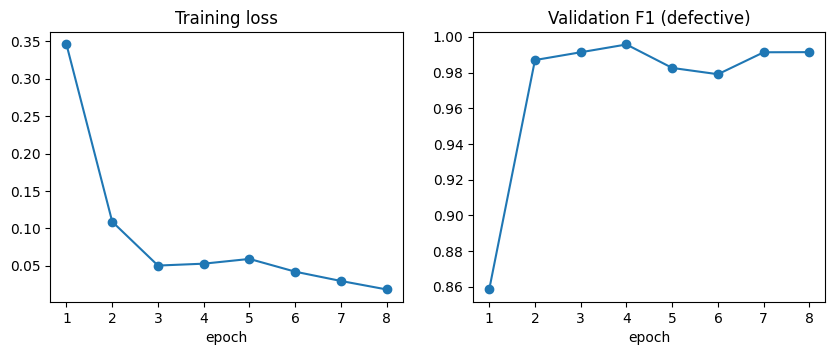

In [13]:
epochs = range(1, EPOCHS + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
left.plot(epochs, history["train_loss"], marker="o")
left.set_title("Training loss"); left.set_xlabel("epoch")
right.plot(epochs, history["val_f1"], marker="o")
right.set_title("Validation F1 (defective)"); right.set_xlabel("epoch")
plt.savefig("reports/training_curve.png", dpi=120, bbox_inches="tight")
plt.show()

              precision    recall  f1-score   support

   defective     0.9832    1.0000    0.9915       117
      normal     1.0000    0.9744    0.9870        78

    accuracy                         0.9897       195
   macro avg     0.9916    0.9872    0.9893       195
weighted avg     0.9899    0.9897    0.9897       195

false negatives (missed defects): 0
false positives (false alarms)  : 2


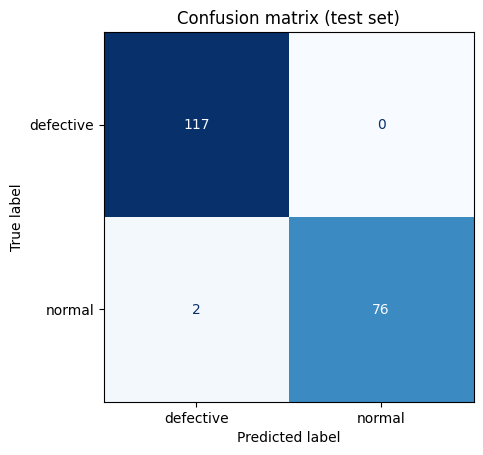

In [14]:
test_probs, y_true = predict(test_loader)
y_pred = test_probs.argmax(1)

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)

cm = confusion_matrix(y_true, y_pred)
false_negatives = cm[0, 1]
false_positives = cm[1, 0]
print("false negatives (missed defects):", false_negatives)
print("false positives (false alarms)  :", false_positives)

ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.savefig("reports/confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

with open("reports/metrics.txt", "w") as f:
    f.write(f"Test set: {len(y_true)} images\n\n{report}\n")
    f.write(f"false negatives (missed defects): {false_negatives}\n")
    f.write(f"false positives (false alarms): {false_positives}\n")

False negatives: defective predicted normal: none


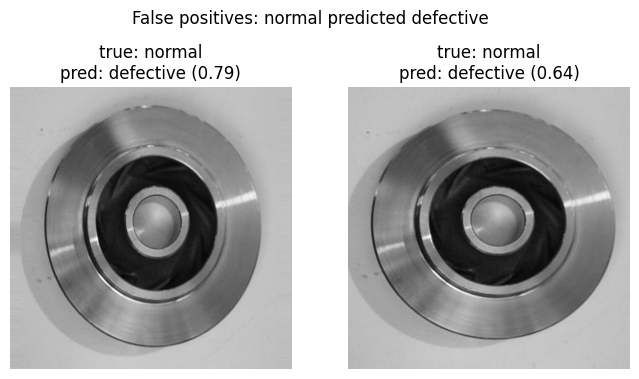

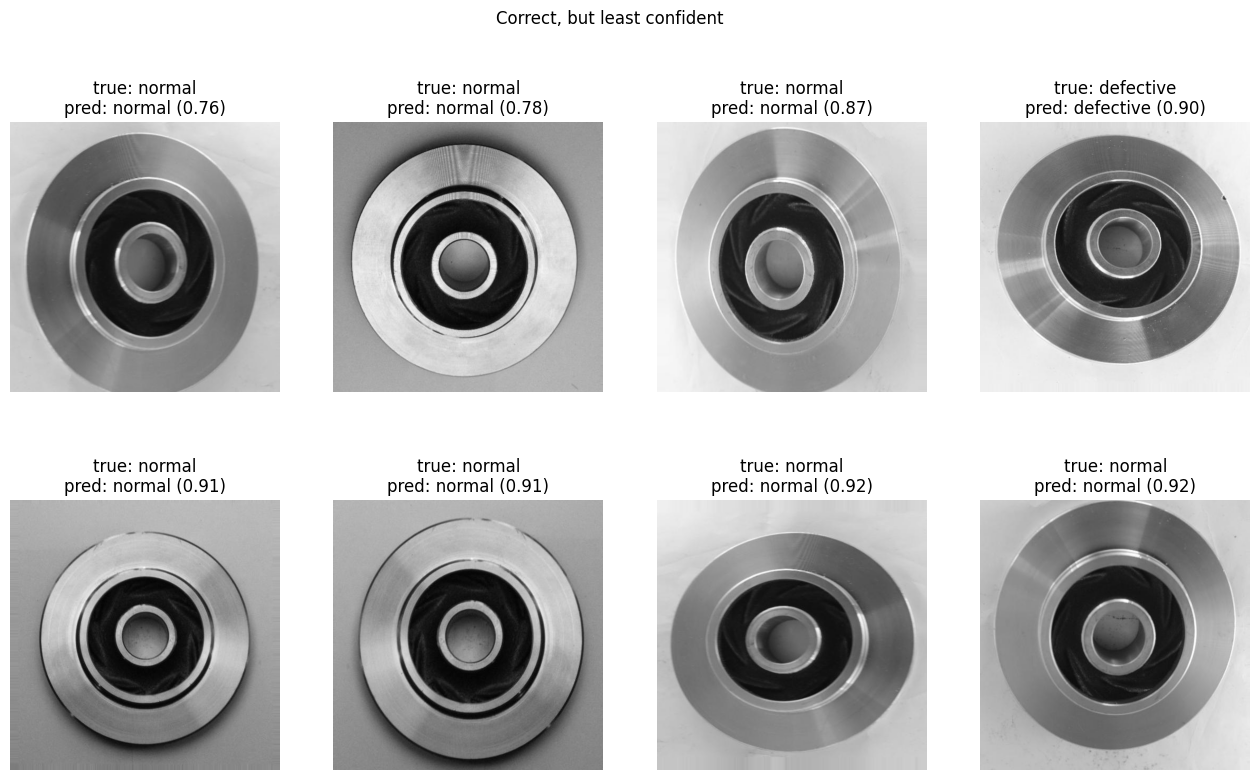

In [15]:
test_paths = [full.samples[i][0] for i in test_idx]
confidence = test_probs.max(1)

def show(indices, title, filename):
    if len(indices) == 0:
        print(f"{title}: none"); return
    cols = min(len(indices), 4)
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.5 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(Image.open(test_paths[i]), cmap="gray")
        ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({confidence[i]:.2f})")
    fig.suptitle(title)
    plt.savefig(f"reports/{filename}", dpi=100, bbox_inches="tight")
    plt.show()

fn = np.where((y_true == 0) & (y_pred == 1))[0]
fp = np.where((y_true == 1) & (y_pred == 0))[0]
least_sure = [i for i in np.argsort(confidence) if y_pred[i] == y_true[i]][:8]

show(fn[:8], "False negatives: defective predicted normal", "false_negatives.png")
show(fp[:8], "False positives: normal predicted defective", "false_positives.png")
show(least_sure, "Correct, but least confident", "low_confidence.png")

In [16]:
import onnxruntime as ort

model = model.cpu().eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
torch.onnx.export(
    model, dummy, "model.onnx",
    input_names=["input"], output_names=["logits"],
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17,
    dynamo=False,
)

session = ort.InferenceSession("model.onnx", providers=["CPUExecutionProvider"])
onnx_pred = np.concatenate([session.run(None, {"input": x.numpy()})[0].argmax(1) for x, _ in test_loader])
agreement = (onnx_pred == y_pred).mean()
print(f"ONNX vs PyTorch agreement on the test set: {agreement:.2%}")
assert agreement > 0.99, "ONNX model does not match the PyTorch model"

one_image = dummy.numpy()
session.run(None, {"input": one_image})
start = time.perf_counter()
for _ in range(50):
    session.run(None, {"input": one_image})
latency_ms = (time.perf_counter() - start) / 50 * 1000
size_mb = os.path.getsize("model.onnx") / 1e6
print(f"model size: {size_mb:.1f} MB   CPU latency: {latency_ms:.1f} ms per image")

with open("reports/metrics.txt", "a") as f:
    f.write(f"\nONNX model size: {size_mb:.1f} MB\n")
    f.write(f"CPU latency (Colab CPU, 1 image): {latency_ms:.1f} ms\n")

/tmp/ipykernel_1696/200461907.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX vs PyTorch agreement on the test set: 100.00%
model size: 44.7 MB   CPU latency: 32.6 ms per image


In [17]:
os.makedirs("examples", exist_ok=True)
example_files = {}
for class_index, name in enumerate(CLASS_NAMES):
    source = test_paths[np.where(y_true == class_index)[0][0]]
    example_files[name] = f"examples/{name}{os.path.splitext(source)[1]}"
    shutil.copy(source, example_files[name])
print(example_files)

{'defective': 'examples/defective.jpeg', 'normal': 'examples/normal.jpeg'}


In [18]:
if not os.path.exists("app.py"):
    print("app.py not found")
else:
    import requests

    url = "http://127.0.0.1:8000"
    server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--port", "8000"])
    for _ in range(30):
        try:
            requests.get(f"{url}/health"); break
        except requests.ConnectionError:
            time.sleep(1)
    print("health ->", requests.get(f"{url}/health").json())

    predictions = {}
    for name, path in example_files.items():
        with open(path, "rb") as f:
            response = requests.post(f"{url}/predict", files={"file": (os.path.basename(path), f, "image/jpeg")})
        predictions[os.path.basename(path)] = response.json()
        print(f"{path} (true: {name}) ->", response.status_code, response.json())

    bad = requests.post(f"{url}/predict", files={"file": ("notes.txt", b"hello", "text/plain")})
    print("text file ->", bad.status_code, bad.json())
    server.terminate()

    with open("examples/predictions.json", "w") as f:
        json.dump(predictions, f, indent=2)

    tests = subprocess.run([sys.executable, "-m", "pytest", "-q", "test_app.py"], capture_output=True, text=True)
    print(tests.stdout, tests.stderr)

health -> {'status': 'ok'}
examples/defective.jpeg (true: defective) -> 200 {'predicted_class': 'defective', 'confidence': 1.0}
examples/normal.jpeg (true: normal) -> 200 {'predicted_class': 'normal', 'confidence': 0.9983}
text file -> 400 {'detail': 'File must be an image (JPEG or PNG).'}
....                                                                     [100%]
4 passed in 0.87s
 


In [19]:
!zip -qr outputs.zip model.onnx reports examples
from google.colab import files
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>